In [372]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

In [373]:
disp = pd.read_csv("prescription_dispensing_records.csv")
demo = pd.read_csv("patient_demographics.csv")
diagnosis = pd.read_csv("diagnosis_codes.csv")
intervention = pd.read_csv("pharmacist_intervention_log.csv")

In [374]:
disp["dispensing_date"] = pd.to_datetime(
    disp["dispensing_date"]
)

diagnosis["claim_date"] = pd.to_datetime(
    diagnosis["claim_date"]
)

intervention["intervention_date"] = pd.to_datetime(
    intervention["intervention_date"]
)

In [375]:
disp = disp.sort_values(
    ["patient_id", "drug_name", "dispensing_date"]
)

In [376]:
disp["expected_end_date"] = (
    disp["dispensing_date"]
    + pd.to_timedelta(
        disp["days_supply"],
        unit="D"
    )
)

In [377]:
disp["next_dispensing_date"] = (
    disp
    .groupby(
        ["patient_id", "drug_name"]
    )["dispensing_date"]
    .shift(-1)
)

In [378]:
disp["refill_gap"] = (
    disp["next_dispensing_date"]
    - disp["expected_end_date"]
).dt.days

In [379]:
disp["positive_gap"] = (
    disp["refill_gap"]
    .clip(lower=0)
)

In [380]:
disp

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,expected_end_date,next_dispensing_date,refill_gap,positive_gap
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,2022-05-11,2022-05-17,6.0,6.0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,2022-06-16,2022-06-17,1.0,1.0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,2022-07-17,2022-07-24,7.0,7.0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,2022-08-23,2022-08-22,-1.0,0.0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,2022-09-21,2022-09-25,4.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,2023-01-10,2023-01-18,8.0,8.0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,2023-02-17,NaT,NaN,NaN
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,2023-01-16,2023-01-21,5.0,5.0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,2023-04-21,2023-05-17,26.0,26.0


In [381]:
disp["gap_7plus"] = (
    disp["positive_gap"] >= 7
).astype(int)

disp["gap_14plus"] = (
    disp["positive_gap"] >= 14
).astype(int)

disp["gap_30plus"] = (
    disp["positive_gap"] >= 30
).astype(int)

In [382]:
disp

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,expected_end_date,next_dispensing_date,refill_gap,positive_gap,gap_7plus,gap_14plus,gap_30plus
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,2022-05-11,2022-05-17,6.0,6.0,0,0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,2022-06-16,2022-06-17,1.0,1.0,0,0,0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,2022-07-17,2022-07-24,7.0,7.0,1,0,0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,2022-08-23,2022-08-22,-1.0,0.0,0,0,0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,2022-09-21,2022-09-25,4.0,4.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,2023-01-10,2023-01-18,8.0,8.0,1,0,0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,2023-02-17,NaT,NaN,NaN,0,0,0
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,2023-01-16,2023-01-21,5.0,5.0,0,0,0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,2023-04-21,2023-05-17,26.0,26.0,1,1,0


In [383]:
disp["late"] = (
    disp["positive_gap"] > 0
).astype(int)

In [384]:
disp

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,expected_end_date,next_dispensing_date,refill_gap,positive_gap,gap_7plus,gap_14plus,gap_30plus,late
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,2022-05-11,2022-05-17,6.0,6.0,0,0,0,1
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,2022-06-16,2022-06-17,1.0,1.0,0,0,0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,2022-07-17,2022-07-24,7.0,7.0,1,0,0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,2022-08-23,2022-08-22,-1.0,0.0,0,0,0,0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,2022-09-21,2022-09-25,4.0,4.0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,2023-01-10,2023-01-18,8.0,8.0,1,0,0,1
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,2023-02-17,NaT,NaN,NaN,0,0,0,0
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,2023-01-16,2023-01-21,5.0,5.0,0,0,0,1
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,2023-04-21,2023-05-17,26.0,26.0,1,1,0,1


In [385]:
group_id = (
    disp.groupby(
        ["patient_id", "drug_name"]
    )["late"]
    .transform(
        lambda x: x.ne(x.shift()).cumsum()
    )
)

In [386]:
run_length = (
    disp.groupby(
        ["patient_id", "drug_name", group_id]
    )["late"]
    .transform("size")
)

In [387]:
run_length

0        3
1        3
2        3
3        1
4        2
        ..
36265    1
36266    1
36267    2
36268    2
36269    1
Name: late, Length: 36270, dtype: int64

In [388]:
disp["late_run_length"] = np.where(
    disp["late"] == 1,
    run_length,
    0
)

In [389]:
disp

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,expected_end_date,next_dispensing_date,refill_gap,positive_gap,gap_7plus,gap_14plus,gap_30plus,late,late_run_length
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,2022-05-11,2022-05-17,6.0,6.0,0,0,0,1,3
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,2022-06-16,2022-06-17,1.0,1.0,0,0,0,1,3
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,2022-07-17,2022-07-24,7.0,7.0,1,0,0,1,3
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,2022-08-23,2022-08-22,-1.0,0.0,0,0,0,0,0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,2022-09-21,2022-09-25,4.0,4.0,0,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,2023-01-10,2023-01-18,8.0,8.0,1,0,0,1,1
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,2023-02-17,NaT,NaN,NaN,0,0,0,0,0
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,2023-01-16,2023-01-21,5.0,5.0,0,0,0,1,2
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,2023-04-21,2023-05-17,26.0,26.0,1,1,0,1,2


In [390]:
consecutive_features = (
    disp.groupby("patient_id")
    .agg(
        consecutive_late_refills=(
            "late_run_length",
            "max"
        )
    )
    .reset_index()
)

In [391]:
consecutive_features

,patient_id,consecutive_late_refills
0,PAT000001,3
1,PAT000002,2
2,PAT000003,0
3,PAT000004,4
4,PAT000005,8
...,...,...
2995,PAT002996,1
2996,PAT002997,1
2997,PAT002998,4
2998,PAT002999,2


In [392]:
refill_features = (
    disp.groupby("patient_id")
    .agg(
        median_refill_gap=(
            "positive_gap",
            "median"
        ),

        std_refill_gap=(
            "positive_gap",
            "std"
        ),

        gaps_7plus=(
            "gap_7plus",
            "sum"
        ),

        gaps_14plus=(
            "gap_14plus",
            "sum"
        ),

        gaps_30plus=(
            "gap_30plus",
            "sum"
        ),

        number_of_unique_drugs=(
            "drug_name",
            "nunique"
        )
    )
    .reset_index()
)

In [393]:
refill_features

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs
0,PAT000001,1.5,4.964157,3,1,0,3
1,PAT000002,0.5,5.757461,5,1,0,2
2,PAT000003,NaN,NaN,0,0,0,1
3,PAT000004,7.0,9.777835,6,4,0,2
4,PAT000005,12.0,8.888194,7,4,0,1
...,...,...,...,...,...,...,...
2995,PAT002996,0.0,1.788854,0,0,0,1
2996,PAT002997,0.0,3.940530,2,0,0,2
2997,PAT002998,10.0,8.467257,5,3,0,3
2998,PAT002999,1.0,3.435113,1,0,0,1


In [394]:
refill_features["refill_gap_cv"] = (
    refill_features["std_refill_gap"]
    /
    refill_features["median_refill_gap"]
    .replace(0, np.nan)
)

In [395]:
refill_features["refill_gap_cv"] = (
    refill_features["refill_gap_cv"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

In [396]:
refill_features

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921
2,PAT000003,NaN,NaN,0,0,0,1,0.000000
3,PAT000004,7.0,9.777835,6,4,0,2,1.396834
4,PAT000005,12.0,8.888194,7,4,0,1,0.740683
...,...,...,...,...,...,...,...,...
2995,PAT002996,0.0,1.788854,0,0,0,1,0.000000
2996,PAT002997,0.0,3.940530,2,0,0,2,0.000000
2997,PAT002998,10.0,8.467257,5,3,0,3,0.846726
2998,PAT002999,1.0,3.435113,1,0,0,1,3.435113


### Survival Analysis

In [397]:
LANDMARK = pd.Timestamp("2024-01-01")

In [398]:
before_landmark = disp[
    disp["dispensing_date"] < LANDMARK
].copy()

In [399]:
before_landmark

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,expected_end_date,next_dispensing_date,refill_gap,positive_gap,gap_7plus,gap_14plus,gap_30plus,late,late_run_length
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,2022-05-11,2022-05-17,6.0,6.0,0,0,0,1,3
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,2022-06-16,2022-06-17,1.0,1.0,0,0,0,1,3
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,2022-07-17,2022-07-24,7.0,7.0,1,0,0,1,3
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,2022-08-23,2022-08-22,-1.0,0.0,0,0,0,0,0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,2022-09-21,2022-09-25,4.0,4.0,0,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,2023-01-10,2023-01-18,8.0,8.0,1,0,0,1,1
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,2023-02-17,NaT,NaN,NaN,0,0,0,0,0
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,2023-01-16,2023-01-21,5.0,5.0,0,0,0,1,2
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,2023-04-21,2023-05-17,26.0,26.0,1,1,0,1,2


In [400]:
last_refill = (
    before_landmark
    .groupby("patient_id")["dispensing_date"]
    .max()
    .reset_index()
)

In [401]:
last_refill

,patient_id,dispensing_date
0,PAT000001,2023-02-03
1,PAT000002,2023-11-02
2,PAT000003,2022-10-23
3,PAT000004,2023-12-18
4,PAT000005,2023-12-24
...,...,...
2995,PAT002996,2023-10-09
2996,PAT002997,2023-11-30
2997,PAT002998,2023-12-29
2998,PAT002999,2023-01-18


In [402]:
last_refill = last_refill.rename(
    columns={
        "dispensing_date":
        "last_refill_date"
    }
)

In [403]:
last_refill["days_since_last_refill"] = (
    LANDMARK -
    last_refill["last_refill_date"]
).dt.days

In [404]:
baseline_start = (
    LANDMARK -
    pd.Timedelta(days=365)
)

In [405]:
baseline = disp[
    (disp["dispensing_date"] >= baseline_start)
    &
    (disp["dispensing_date"] < LANDMARK)
].copy()

In [406]:
baseline

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,expected_end_date,next_dispensing_date,refill_gap,positive_gap,gap_7plus,gap_14plus,gap_30plus,late,late_run_length
10,PAT000001,Levothyroxine,2023-02-03,90,30,CVS0354,73963-275-36,2023-05-04,NaT,NaN,NaN,0,0,0,0,0
17,PAT000002,Amlodipine,2023-04-28,30,30,CVS0411,73453-157-60,2023-05-28,2023-05-28,0.0,0.0,0,0,0,0,0
18,PAT000002,Amlodipine,2023-05-28,30,30,CVS0390,61093-816-38,2023-06-27,2023-06-27,0.0,0.0,0,0,0,0,0
19,PAT000002,Amlodipine,2023-06-27,30,30,CVS0033,71800-247-21,2023-07-27,2023-08-04,8.0,8.0,1,0,0,1,1
20,PAT000002,Amlodipine,2023-08-04,30,30,CVS0083,68425-246-32,2023-09-03,2023-09-01,-2.0,0.0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36254,PAT002998,Levothyroxine,2023-12-29,90,30,CVS0320,19846-331-42,2024-03-28,2024-04-16,19.0,19.0,1,1,0,1,4
36260,PAT002998,Metformin,2023-03-22,90,30,CVS0222,73151-779-53,2023-06-20,NaT,NaN,NaN,0,0,0,0,0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,2023-02-17,NaT,NaN,NaN,0,0,0,0,0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,2023-04-21,2023-05-17,26.0,26.0,1,1,0,1,2


In [407]:
baseline["covered_days"] = (
    baseline["days_supply"]
)

In [408]:
baseline

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,expected_end_date,next_dispensing_date,refill_gap,positive_gap,gap_7plus,gap_14plus,gap_30plus,late,late_run_length,covered_days
10,PAT000001,Levothyroxine,2023-02-03,90,30,CVS0354,73963-275-36,2023-05-04,NaT,NaN,NaN,0,0,0,0,0,90
17,PAT000002,Amlodipine,2023-04-28,30,30,CVS0411,73453-157-60,2023-05-28,2023-05-28,0.0,0.0,0,0,0,0,0,30
18,PAT000002,Amlodipine,2023-05-28,30,30,CVS0390,61093-816-38,2023-06-27,2023-06-27,0.0,0.0,0,0,0,0,0,30
19,PAT000002,Amlodipine,2023-06-27,30,30,CVS0033,71800-247-21,2023-07-27,2023-08-04,8.0,8.0,1,0,0,1,1,30
20,PAT000002,Amlodipine,2023-08-04,30,30,CVS0083,68425-246-32,2023-09-03,2023-09-01,-2.0,0.0,0,0,0,0,0,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36254,PAT002998,Levothyroxine,2023-12-29,90,30,CVS0320,19846-331-42,2024-03-28,2024-04-16,19.0,19.0,1,1,0,1,4,90
36260,PAT002998,Metformin,2023-03-22,90,30,CVS0222,73151-779-53,2023-06-20,NaT,NaN,NaN,0,0,0,0,0,90
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,2023-02-17,NaT,NaN,NaN,0,0,0,0,0,30
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,2023-04-21,2023-05-17,26.0,26.0,1,1,0,1,2,90


In [409]:
recent_90_start = (
    LANDMARK -
    pd.Timedelta(days=90)
)

recent_90 = baseline[
    baseline["dispensing_date"] >= recent_90_start
]

In [410]:
recent_90_pdc = (
    recent_90
    .groupby("patient_id")["covered_days"]
    .sum()
    .clip(upper=90)
    / 90
)

In [411]:
recent_90_pdc = (
    recent_90_pdc
    .reset_index(
        name="recent_90d_pdc"
    )
)

In [412]:
recent_90_pdc

,patient_id,recent_90d_pdc
0,PAT000002,1.000000
1,PAT000004,1.000000
2,PAT000005,1.000000
3,PAT000006,1.000000
4,PAT000007,1.000000
...,...,...
1570,PAT002994,1.000000
1571,PAT002995,0.666667
1572,PAT002996,0.333333
1573,PAT002997,1.000000


In [413]:
recent_180_start = (
    LANDMARK -
    pd.Timedelta(days=180)
)

recent_180 = baseline[
    baseline["dispensing_date"] >= recent_180_start
]

In [414]:
recent_180_pdc = (
    recent_180
    .groupby("patient_id")["covered_days"]
    .sum()
    .clip(upper=180)
    / 180
)

In [415]:
recent_180_pdc = (
    recent_180_pdc
    .reset_index(
        name="recent_180d_pdc"
    )
)

In [416]:
recent_pdc = recent_90_pdc.merge(
    recent_180_pdc,
    on="patient_id",
    how="outer"
)

In [417]:
recent_pdc["adherence_trend"] = (
    recent_pdc["recent_90d_pdc"]
    -
    recent_pdc["recent_180d_pdc"]
)

In [418]:
recent_pdc

,patient_id,recent_90d_pdc,recent_180d_pdc,adherence_trend
0,PAT000002,1.000000,1.000000,0.000000
1,PAT000004,1.000000,1.000000,0.000000
2,PAT000005,1.000000,1.000000,0.000000
3,PAT000006,1.000000,1.000000,0.000000
4,PAT000007,1.000000,1.000000,0.000000
...,...,...,...,...
1987,PAT002994,1.000000,1.000000,0.000000
1988,PAT002995,0.666667,0.833333,-0.166667
1989,PAT002996,0.333333,0.666667,-0.333333
1990,PAT002997,1.000000,1.000000,0.000000


In [419]:
drug_pdc = pd.read_csv(
    "drug_level_pdc.csv"
)

In [420]:
drug_features = (
    drug_pdc
    .groupby("patient_id")
    .agg(
        min_drug_pdc=("pdc", "min"),

        number_of_drugs_below_80_pdc=(
            "pdc",
            lambda x: (x < 0.80).sum()
        )
    )
    .reset_index()
)

In [421]:
pharmacy_features = (
    disp
    .groupby("patient_id")
    .agg(
        number_of_pharmacies=(
            "pharmacy_id",
            "nunique"
        )
    )
    .reset_index()
)

In [422]:
pharm = disp.sort_values(
    ["patient_id", "dispensing_date"]
).copy()

In [423]:
pharm["pharmacy_switch"] = (
    pharm
    .groupby("patient_id")["pharmacy_id"]
    .transform(
        lambda x: x.ne(x.shift()).astype(int)
    )
)

In [424]:
pharm["pharmacy_switch"] = (
    pharm["pharmacy_switch"]
    .where(
        pharm.groupby("patient_id").cumcount() > 0,
        0
    )
)

In [425]:
pharmacy_switch = (
    pharm.groupby("patient_id")
    ["pharmacy_switch"]
    .sum()
    .reset_index(
        name="pharmacy_switch_count"
    )
)

In [426]:
diagnosis_features = (
    diagnosis
    .groupby("patient_id")
    .agg(
        number_of_diagnoses=(
            "icd10_code",
            "count"
        ),

        number_of_unique_icd10=(
            "icd10_code",
            "nunique"
        )
    )
    .reset_index()
)

In [427]:
diagnosis_features

,patient_id,number_of_diagnoses,number_of_unique_icd10
0,PAT000001,1,1
1,PAT000003,1,1
2,PAT000004,1,1
3,PAT000008,1,1
4,PAT000009,1,1
...,...,...,...
1995,PAT002992,1,1
1996,PAT002993,1,1
1997,PAT002996,1,1
1998,PAT002998,1,1


In [428]:
intervention_baseline = intervention[
    intervention["intervention_date"] < LANDMARK
].copy()

In [429]:
intervention_features = (
    intervention_baseline
    .groupby("patient_id")
    .agg(
        previous_interventions=(
            "intervention_id",
            "count"
        )
    )
    .reset_index()
)

In [430]:
intervention["outcome_code"].value_counts()

outcome_code
REFILL_MADE    2484
NO_RESPONSE    1253
OPTED_OUT       519
ESCALATED       403
RESOLVED        341
Name: count, dtype: int64

In [431]:
intervention_baseline

,intervention_id,patient_id,intervention_date,intervention_type_raw,outcome_code,pharmacist_id
0,INT0000001,PAT001567,2023-07-12,texted patient,NO_RESPONSE,PH0185
1,INT0000002,PAT001108,2023-06-04,phone call,NO_RESPONSE,PH0023
2,INT0000003,PAT001652,2023-10-12,texted patient,NO_RESPONSE,PH0038
3,INT0000004,PAT001238,2023-07-26,phone call,RESOLVED,PH0113
4,INT0000005,PAT002917,2022-10-02,postal reminder,NO_RESPONSE,PH0158
...,...,...,...,...,...,...
4995,INT0004996,PAT000340,2022-10-09,sent letter,OPTED_OUT,PH0002
4996,INT0004997,PAT001529,2023-05-28,phone call,NO_RESPONSE,PH0141
4997,INT0004998,PAT000193,2023-09-23,sent letter,REFILL_MADE,PH0163
4998,INT0004999,PAT001698,2023-04-13,sent letter,REFILL_MADE,PH0042


In [432]:
intervention_baseline[
    "failed_intervention"
] = (
    intervention_baseline[
        "outcome_code"
    ] == "NO_RESPONSE"
).astype(int)

In [433]:
failed_interventions = (
    intervention_baseline
    .groupby("patient_id")
    ["failed_intervention"]
    .sum()
    .reset_index(
        name="previous_failed_interventions"
    )
)

In [434]:
last_intervention = (
    intervention_baseline
    .groupby("patient_id")
    ["intervention_date"]
    .max()
    .reset_index()
)

In [435]:
last_intervention = last_intervention.rename(
    columns={
        "intervention_date":
        "last_intervention_date"
    }
)

In [436]:
last_intervention[
    "days_since_last_intervention"
] = (
    LANDMARK -
    last_intervention[
        "last_intervention_date"
    ]
).dt.days

In [437]:
patient_features = (
    refill_features
    .merge(
        consecutive_features,
        on="patient_id",
        how="left"
    )
    .merge(
        last_refill[
            [
                "patient_id",
                "days_since_last_refill"
            ]
        ],
        on="patient_id",
        how="left"
    )
    .merge(
        recent_pdc[
            [
                "patient_id",
                "recent_90d_pdc",
                "recent_180d_pdc",
                "adherence_trend"
            ]
        ],
        on="patient_id",
        how="left"
    )
    .merge(
        drug_features,
        on="patient_id",
        how="left"
    )
    .merge(
        pharmacy_features,
        on="patient_id",
        how="left"
    )
    .merge(
        pharmacy_switch,
        on="patient_id",
        how="left"
    )
    .merge(
        diagnosis_features,
        on="patient_id",
        how="left"
    )
    .merge(
        intervention_features,
        on="patient_id",
        how="left"
    )
    .merge(
        failed_interventions,
        on="patient_id",
        how="left"
    )
    .merge(
        last_intervention[
            [
                "patient_id",
                "days_since_last_intervention"
            ]
        ],
        on="patient_id",
        how="left"
    )
)

In [438]:
zero_features = [
    "number_of_diagnoses",
    "number_of_unique_icd10",
    "previous_interventions",
    "previous_failed_interventions",
    "number_of_pharmacies",
    "pharmacy_switch_count",
    "number_of_drugs_below_80_pdc"
]

In [439]:
patient_features[zero_features] = (
    patient_features[zero_features]
    .fillna(0)
)

In [440]:
continuous_features = [
    "median_refill_gap",
    "std_refill_gap",
    "refill_gap_cv",
    "recent_90d_pdc",
    "recent_180d_pdc",
    "adherence_trend",
    "min_drug_pdc"
]

In [441]:
for col in continuous_features:
    patient_features[col] = (
        patient_features[col]
        .fillna(
            patient_features[col].median()
        )
    )

In [442]:
final_df=pd.read_csv('final_df.csv')

In [443]:
existing_adherence = final_df[
    [
        "patient_id",
        "pdc",
        "CMA",
        "CMG"
    ]
]

In [444]:
patient_features = patient_features.merge(
    existing_adherence,
    on="patient_id",
    how="left"
)

In [445]:
patient_features=patient_features[patient_features['patient_id'].isin(final_df['patient_id'])]
patient_features

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,number_of_pharmacies,pharmacy_switch_count,number_of_diagnoses,number_of_unique_icd10,previous_interventions,previous_failed_interventions,days_since_last_intervention,pdc,CMA,CMG
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,16,15,1.0,1.0,1.0,0.0,314.0,0.979381,1.932990,0.020619
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,16,15,0.0,0.0,1.0,0.0,110.0,0.960573,1.218638,0.039427
3,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,14,13,1.0,1.0,3.0,0.0,186.0,0.963048,1.454965,0.036952
4,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,10,9,0.0,0.0,3.0,0.0,182.0,0.878698,0.887574,0.121302
5,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,6,5,0.0,0.0,3.0,2.0,228.0,0.922131,0.983607,0.077869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,6,5,1.0,1.0,1.0,1.0,209.0,0.978142,0.983607,0.021858
2996,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,10,9,0.0,0.0,0.0,0.0,NaN,0.996276,1.284916,0.003724
2997,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,12,11,1.0,1.0,0.0,0.0,NaN,0.942113,1.389291,0.057887
2998,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,6,5,1.0,1.0,2.0,0.0,38.0,0.930851,0.957447,0.069149


In [446]:
features = [
    # Existing adherence
    "pdc",
    "CMA",
    "CMG",

    # Refill behavior
    "median_refill_gap",
    "std_refill_gap",
    "refill_gap_cv",
    "gaps_7plus",
    "gaps_14plus",
    "gaps_30plus",
    "consecutive_late_refills",

    # Medication complexity
    "number_of_unique_drugs",
    "min_drug_pdc",
    "number_of_drugs_below_80_pdc",

    # Recent adherence
    "recent_90d_pdc",
    "recent_180d_pdc",
    "adherence_trend",
    "days_since_last_refill",

    # Pharmacy
    "number_of_pharmacies",
    "pharmacy_switch_count",

    # Clinical
    "number_of_diagnoses",
    "number_of_unique_icd10",

    # Previous pharmacist intervention
    "previous_interventions",
    "previous_failed_interventions",
    "days_since_last_intervention"
]

In [447]:
patient_features["risk_score"] = 0

In [448]:
patient_features

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,pharmacy_switch_count,number_of_diagnoses,number_of_unique_icd10,previous_interventions,previous_failed_interventions,days_since_last_intervention,pdc,CMA,CMG,risk_score
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,15,1.0,1.0,1.0,0.0,314.0,0.979381,1.932990,0.020619,0
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,15,0.0,0.0,1.0,0.0,110.0,0.960573,1.218638,0.039427,0
3,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,13,1.0,1.0,3.0,0.0,186.0,0.963048,1.454965,0.036952,0
4,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,9,0.0,0.0,3.0,0.0,182.0,0.878698,0.887574,0.121302,0
5,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,5,0.0,0.0,3.0,2.0,228.0,0.922131,0.983607,0.077869,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,5,1.0,1.0,1.0,1.0,209.0,0.978142,0.983607,0.021858,0
2996,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,9,0.0,0.0,0.0,0.0,NaN,0.996276,1.284916,0.003724,0
2997,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,11,1.0,1.0,0.0,0.0,NaN,0.942113,1.389291,0.057887,0
2998,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,5,1.0,1.0,2.0,0.0,38.0,0.930851,0.957447,0.069149,0


In [ ]:
# patient_features.loc[
#     patient_features["pdc"] < 0.80,
#     "risk_score"
# ] += 2

In [ ]:
# patient_features.loc[
#     patient_features["recent_90d_pdc"] < 0.80,
#     "risk_score"
# ] += 2

In [ ]:
# patient_features.loc[
#     patient_features["gaps_14plus"] >= 2,
#     "risk_score"
# ] += 2

In [ ]:
# patient_features.loc[
#     patient_features["gaps_30plus"] >= 1,
#     "risk_score"
# ] += 2

In [ ]:
# patient_features.loc[
#     patient_features["adherence_trend"] < -0.10,
#     "risk_score"
# ] += 2

In [ ]:
# patient_features.loc[
#     patient_features["days_since_last_refill"] >= 14,
#     "risk_score"
# ] += 2

In [ ]:
# def assign_risk(score):

#     if score >= 5:
#         return "High Risk"

#     elif score >= 2:
#         return "Medium Risk"

#     else:
#         return "Low Risk"

In [ ]:
# patient_features["risk_tier"] = (
#     patient_features["risk_score"]
#     .apply(assign_risk)
# )

In [344]:
patient_features

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,number_of_unique_icd10,previous_interventions,previous_failed_interventions,days_since_last_intervention,pdc,CMA,CMG,risk_score,risk_tier,behavior_cluster
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,1.0,1.0,0.0,314.0,0.979381,1.932990,0.020619,2,Medium Risk,0
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,0.0,1.0,0.0,110.0,0.960573,1.218638,0.039427,2,Medium Risk,0
3,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,1.0,3.0,0.0,186.0,0.963048,1.454965,0.036952,4,Medium Risk,2
4,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,0.0,3.0,0.0,182.0,0.878698,0.887574,0.121302,2,Medium Risk,2
5,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,0.0,3.0,2.0,228.0,0.922131,0.983607,0.077869,0,Low Risk,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,1.0,1.0,1.0,209.0,0.978142,0.983607,0.021858,6,High Risk,1
2996,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,0.0,0.0,0.0,NaN,0.996276,1.284916,0.003724,2,Medium Risk,0
2997,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,1.0,0.0,0.0,NaN,0.942113,1.389291,0.057887,2,Medium Risk,2
2998,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,1.0,2.0,0.0,38.0,0.930851,0.957447,0.069149,2,Medium Risk,0


#### Data driven approach to select risk tier

In [450]:
# survival_df = survival_df.drop(
#     columns=["risk_score", "risk_tier"],
#     errors="ignore"
# )

In [451]:
# survival_df

In [452]:
# survival_df
patient_features

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,pharmacy_switch_count,number_of_diagnoses,number_of_unique_icd10,previous_interventions,previous_failed_interventions,days_since_last_intervention,pdc,CMA,CMG,risk_score
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,15,1.0,1.0,1.0,0.0,314.0,0.979381,1.932990,0.020619,0
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,15,0.0,0.0,1.0,0.0,110.0,0.960573,1.218638,0.039427,0
3,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,13,1.0,1.0,3.0,0.0,186.0,0.963048,1.454965,0.036952,0
4,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,9,0.0,0.0,3.0,0.0,182.0,0.878698,0.887574,0.121302,0
5,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,5,0.0,0.0,3.0,2.0,228.0,0.922131,0.983607,0.077869,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,5,1.0,1.0,1.0,1.0,209.0,0.978142,0.983607,0.021858,0
2996,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,9,0.0,0.0,0.0,0.0,NaN,0.996276,1.284916,0.003724,0
2997,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,11,1.0,1.0,0.0,0.0,NaN,0.942113,1.389291,0.057887,0
2998,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,5,1.0,1.0,2.0,0.0,38.0,0.930851,0.957447,0.069149,0


In [454]:
cluster_features = [
    "pdc",
    "median_refill_gap",
    "refill_gap_cv",
    "gaps_14plus",
    "gaps_30plus",
    "recent_90d_pdc",
    "recent_180d_pdc",
    "adherence_trend",
    "days_since_last_refill"
]

In [455]:
X = patient_features[
    cluster_features
].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [456]:
X.isna().sum()

pdc                       0
median_refill_gap         0
refill_gap_cv             0
gaps_14plus               0
gaps_30plus               0
recent_90d_pdc            0
recent_180d_pdc           0
adherence_trend           0
days_since_last_refill    0
dtype: int64

In [457]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

patient_features["behavior_cluster"] = (
    kmeans.fit_predict(X_scaled)
)

In [458]:
cluster_profile = (
    patient_features
    .groupby("behavior_cluster")
    [cluster_features]
    .mean()
)

print(cluster_profile)

                       pdc  median_refill_gap  refill_gap_cv  gaps_14plus  \
behavior_cluster                                                            
0                 0.955583           2.955469       1.871041     0.699342   
1                 0.942878           2.827586       1.429901     0.336207   
2                 0.923201           8.975022       1.231954     3.827832   

                  gaps_30plus  recent_90d_pdc  recent_180d_pdc  \
behavior_cluster                                                 
0                         0.0        0.999801         0.899980   
1                         0.0        0.474138         0.820402   
2                         0.0        1.000000         0.909753   

                  adherence_trend  days_since_last_refill  
behavior_cluster                                           
0                        0.006077              216.371189  
1                       -0.346264               58.396552  
2                        0.036574          

In [505]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, kmeans.labels_)

print("Silhouette Score:", score)

Silhouette Score: 0.23986393414957108


In [507]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 12):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"K = {k}: {score:.3f}")

K = 2: 0.207
K = 3: 0.240
K = 4: 0.283
K = 5: 0.278
K = 6: 0.306
K = 7: 0.322
K = 8: 0.291
K = 9: 0.285
K = 10: 0.290
K = 11: 0.292


In [459]:
future = disp[
    disp["dispensing_date"] >= LANDMARK
].copy()

In [460]:
future_gap = future[
    future["positive_gap"] >= 14
]

In [461]:
first_gap = (
    future_gap
    .groupby("patient_id")
    ["dispensing_date"]
    .min()
    .reset_index()
)

In [462]:
first_gap = first_gap.rename(
    columns={
        "dispensing_date":
        "first_gap_date"
    }
)

In [463]:
first_gap["time_to_gap_days"] = (
    first_gap["first_gap_date"]
    - LANDMARK
).dt.days

In [464]:
first_gap["event"] = 1

In [465]:
study_end = disp[
    "dispensing_date"
].max()

In [466]:
survival_df = patient_features.merge(
    first_gap[
        [
            "patient_id",
            "first_gap_date",
            "time_to_gap_days",
            "event"
        ]
    ],
    on="patient_id",
    how="left"
)

In [467]:
survival_df["event"] = (
    survival_df["event"]
    .fillna(0)
)

In [468]:
survival_df["time_to_gap_days"] = (
    survival_df["time_to_gap_days"]
    .fillna(
        (study_end - LANDMARK).days
    )
)

In [469]:
cox_features = [
    "pdc",
    "recent_90d_pdc",
    "recent_180d_pdc",
    "adherence_trend",
    "median_refill_gap",
    "refill_gap_cv",
    "gaps_14plus",
    "consecutive_late_refills",
    "number_of_unique_drugs",
    "min_drug_pdc",
    "days_since_last_refill",
    "number_of_pharmacies",
    "number_of_unique_icd10",
    "previous_interventions",
    "previous_failed_interventions"
]



























In [470]:
cox_df = survival_df[
    ["patient_id", "time_to_gap_days", "event"] + cox_features
].copy()

In [471]:
cox_df = (
    cox_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

In [472]:
cox_df = (
    cox_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

In [473]:

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    cox_df,
    test_size=0.30,
    random_state=42,
    stratify=cox_df["event"]
)

In [474]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_df[cox_features] = scaler.fit_transform(
    train_df[cox_features]
)

test_df[cox_features] = scaler.transform(
    test_df[cox_features]
)

In [475]:


from lifelines import CoxPHFitter

cph = CoxPHFitter(penalizer=0.1)

cph.fit(
    train_df[
        ["time_to_gap_days", "event"] + cox_features
    ],
    duration_col="time_to_gap_days",
    event_col="event"
)

cph.print_summary()

<lifelines.CoxPHFitter: fitted with 2037 total observations, 1473 right-censored observations>
             duration col = 'time_to_gap_days'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 2037
number of events observed = 564
   partial log-likelihood = -3775.87
         time fit was run = 2026-10-01 14:18:00 UTC

---
                               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                      
pdc                           -0.31      0.73      0.04           -0.40           -0.23                0.67                0.80
recent_90d_pdc                 0.07      1.07      0.05           -0.03            0.17                0.97                1.19
recent_180d_pdc                0.09      1.10      0.04            0.00            0.18                1.00                1.20
adherence_trend                0.10      1.11      0.04            0.03            0.18                1.03                1.20
median_refill_gap              0.02      1.02      0.04           -0.07            0.10                0.93                1.11
refill_gap_cv                  0.04      1.05      0.04           -0.03            0.12                0.97                1.13
gaps_14plus                    0.59      1.80      0.04            0.51            0.67                1.66                1.95
consecutive_late_refills       0.15      1.17      0.04            0.07            0.24                1.08                1.27
number_of_unique_drugs        -0.03      0.97      0.05           -0.12            0.06                0.89                1.06
min_drug_pdc                   0.05      1.05      0.05           -0.05            0.15                0.95                1.16
days_since_last_refill        -0.38      0.68      0.05           -0.49           -0.28                0.61                0.76
number_of_pharmacies           0.32      1.37      0.05            0.22            0.41                1.24                1.51
number_of_unique_icd10         0.01      1.01      0.04           -0.07            0.08                0.94                1.08
previous_interventions         0.04      1.04      0.04           -0.04            0.12                0.96                1.13
previous_failed_interventions  0.06      1.06      0.04           -0.01            0.13                0.99                1.14

                               cmp to     z      p  -log2(p)
covariate                                                   
pdc                              0.00 -7.13 <0.005     39.88
recent_90d_pdc                   0.00  1.33   0.18      2.45
recent_180d_pdc                  0.00  2.06   0.04      4.66
adherence_trend                  0.00  2.61   0.01      6.81
median_refill_gap                0.00  0.35   0.73      0.46
refill_gap_cv                    0.00  1.14   0.25      1.99
gaps_14plus                      0.00 14.26 <0.005    150.78
consecutive_late_refills         0.00  3.77 <0.005     12.55
number_of_unique_drugs           0.00 -0.69   0.49      1.02
min_drug_pdc                     0.00  1.02   0.31      1.71
days_since_last_refill           0.00 -7.05 <0.005     39.02
number_of_pharmacies             0.00  6.39 <0.005     32.45
number_of_unique_icd10           0.00  0.14   0.89      0.17
previous_interventions           0.00  1.05   0.29      1.77
previous_failed_interventions    0.00  1.64   0.10      3.32
---
Concordance = 0.86
Partial AIC = 7581.74
log-likelihood ratio test = 870.10 on 15 df
-log2(p) of ll-ratio test = 581.52

In [476]:
HORIZON = 365

train_survival = cph.predict_survival_function(
    train_df[cox_features],
    times=[HORIZON]
)

test_survival = cph.predict_survival_function(
    test_df[cox_features],
    times=[HORIZON]
)


train_df["predicted_risk"] = (
    1 - train_survival.loc[HORIZON].values
)

test_df["predicted_risk"] = (
    1 - test_survival.loc[HORIZON].values
)

In [477]:

from sklearn.tree import DecisionTreeClassifier


train_365 = train_df[
    (train_df["time_to_gap_days"] >= 365) |
    (train_df["event"] == 1)
].copy()

train_365["event_365"] = (
    (train_365["event"] == 1) &
    (train_365["time_to_gap_days"] <= 365)
).astype(int)


tree = DecisionTreeClassifier(
    max_leaf_nodes=3,
    min_samples_leaf=50,
    random_state=42
)

tree.fit(
    train_365[["predicted_risk"]],
    train_365["event_365"]
)

thresholds = sorted(
    tree.tree_.threshold[
        tree.tree_.threshold != -2
    ]
)

thresholds

[np.float64(0.2044106423854828), np.float64(0.3885895311832428)]

In [478]:
low_cutoff = thresholds[0]
high_cutoff = thresholds[1]

def assign_risk(risk):
    if risk < low_cutoff:
        return "Low Risk"
    elif risk < high_cutoff:
        return "Medium Risk"
    else:
        return "High Risk"

In [479]:

train_df["risk_tier"] = (
    train_df["predicted_risk"]
    .apply(assign_risk)
)

test_df["risk_tier"] = (
    test_df["predicted_risk"]
    .apply(assign_risk)
)

In [501]:
train_df

,patient_id,time_to_gap_days,event,pdc,recent_90d_pdc,recent_180d_pdc,adherence_trend,median_refill_gap,refill_gap_cv,gaps_14plus,consecutive_late_refills,number_of_unique_drugs,min_drug_pdc,days_since_last_refill,number_of_pharmacies,number_of_unique_icd10,previous_interventions,previous_failed_interventions,predicted_risk,risk_tier
1966,PAT002026,146.0,1.0,1.120058,0.195216,0.480410,-0.036134,-0.162632,0.233675,2.037508,0.182249,-0.037892,-0.205415,-0.729722,1.217166,-1.439583,0.261564,-0.655141,0.622382,High Risk
1209,PAT001249,821.0,0.0,0.401489,0.195216,0.480410,-0.036134,-0.940288,0.216157,-0.920024,-0.830686,-1.263065,1.516767,2.610544,-0.964964,-1.439583,0.261564,-0.655141,0.028543,Low Risk
1263,PAT001305,821.0,0.0,1.604105,0.195216,0.480410,-0.036134,-0.051538,-0.459532,-0.920024,-0.324219,-0.037892,-1.242011,1.362818,-0.653231,-1.439583,-0.510618,0.905703,0.032781,Low Risk
2602,PAT002684,821.0,0.0,0.160118,0.195216,-1.856997,4.210318,-1.162476,-0.829699,0.065820,-0.830686,1.187281,-0.491440,-0.417791,0.593700,0.694646,0.261564,0.905703,0.274398,Medium Risk
562,PAT000584,104.0,1.0,-1.498291,0.195216,-1.856997,4.210318,2.392524,-0.560460,1.051664,0.182249,-0.037892,-0.840727,-0.430788,-0.497365,0.694646,1.033745,0.905703,0.594849,High Risk
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574,PAT000596,821.0,0.0,1.604105,0.195216,0.480410,-0.036134,-1.162476,-0.829699,-0.920024,-1.843621,-1.263065,2.921987,2.435083,-1.432563,0.694646,-0.510618,-0.655141,0.015564,Low Risk
2883,PAT002974,821.0,0.0,-0.678412,0.195216,0.480410,-0.036134,-0.273726,-0.116431,-0.920024,-1.337153,-1.263065,0.254936,2.714521,-1.432563,0.694646,0.261564,-0.655141,0.028935,Low Risk
1818,PAT001872,821.0,0.0,0.751269,0.195216,0.480410,-0.036134,-1.051382,5.576491,-0.920024,-0.830686,-1.263065,1.925475,0.901419,-1.120830,0.694646,-0.510618,0.905703,0.063945,Low Risk
1405,PAT001448,821.0,0.0,-1.015011,0.195216,0.480410,-0.036134,2.392524,-0.483910,0.065820,-0.830686,-1.263065,-0.138369,1.512285,-1.276697,0.694646,-0.510618,-0.655141,0.096805,Low Risk


In [480]:
test_df.groupby("risk_tier").agg(
    patients=("event", "count"),
    events=("event", "sum"),
    event_rate=("event", "mean"),
    mean_predicted_risk=("predicted_risk", "mean")
)

,patients,events,event_rate,mean_predicted_risk
risk_tier,,,,
High Risk,244,188.0,0.770492,0.628494
Low Risk,477,6.0,0.012579,0.091902
Medium Risk,152,48.0,0.315789,0.294833


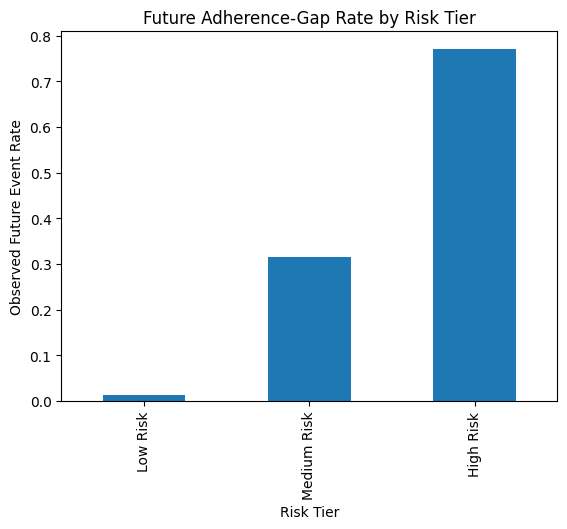

In [481]:
import matplotlib.pyplot as plt

risk_summary = (
    test_df.groupby("risk_tier")["event"]
    .mean()
    .reindex(["Low Risk", "Medium Risk", "High Risk"])
)

risk_summary.plot(kind="bar")

plt.ylabel("Observed Future Event Rate")
plt.xlabel("Risk Tier")
plt.title("Future Adherence-Gap Rate by Risk Tier")
plt.show()

In [482]:
cph.concordance_index_

np.float64(0.8639175195184324)

In [483]:
cph.check_assumptions(
    train_df[
        ["time_to_gap_days", "event"] + cox_features
    ],
    p_value_threshold=0.05
)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'recent_180d_pdc' failed the non-proportional test: p-value is 0.0005.

   Advice: with so few unique values (only 6), you can include `strata=['recent_180d_pdc', ...]` in
the call in `.fit`. See documentation in link [E] below.

2. Variable 'adherence_trend' failed the non-proportional test: p-value is 0.0033.

   Advice 1: the functional form of the variable 'adherence_trend' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'adherence_trend' using pd.cut, and then specify it in
`strata=['adherence_trend', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


3. Variable 'gaps_14plus' failed the non-proportional test: p-value is 0.0092.

   A

[]

In [484]:
cox_features = [
    "pdc",
    "recent_90d_pdc",
    "recent_180d_pdc",
    "adherence_trend",
    "median_refill_gap",
    "refill_gap_cv",
    "gaps_14plus",
    "consecutive_late_refills",
    "number_of_unique_drugs",
    "min_drug_pdc",
    "days_since_last_refill",
    "number_of_pharmacies",
    "pharmacy_switch_count",
    "number_of_unique_icd10",
    "previous_interventions",
    "previous_failed_interventions"
]

In [485]:
print(
    (survival_df["time_to_gap_days"] <= 0).sum()
)

7


In [486]:
cox_df = survival_df[
    survival_df["time_to_gap_days"] > 0
].copy()

In [487]:
cox_df = survival_df[
    [
        "time_to_gap_days",
        "event"
    ] + cox_features
].copy()

In [488]:
cox_df = cox_df.replace(
    [np.inf, -np.inf],
    np.nan
)

cox_df = cox_df.dropna()

In [489]:
cox_df

,time_to_gap_days,event,pdc,recent_90d_pdc,recent_180d_pdc,adherence_trend,median_refill_gap,refill_gap_cv,gaps_14plus,consecutive_late_refills,number_of_unique_drugs,min_drug_pdc,days_since_last_refill,number_of_pharmacies,pharmacy_switch_count,number_of_unique_icd10,previous_interventions,previous_failed_interventions
0,821.0,0.0,0.979381,1.000000,1.000000,0.000000,1.5,3.309438,1,3,3,0.916667,332,16,15,1.0,1.0,0.0
1,211.0,1.0,0.960573,1.000000,1.000000,0.000000,0.5,11.514921,1,2,2,0.946237,60,16,15,0.0,1.0,0.0
2,821.0,0.0,0.963048,1.000000,1.000000,0.000000,7.0,1.396834,4,4,2,0.909931,14,14,13,1.0,3.0,0.0
3,399.0,1.0,0.878698,1.000000,1.000000,0.000000,12.0,0.740683,4,8,1,0.878698,8,10,9,0.0,3.0,0.0
4,821.0,0.0,0.922131,1.000000,1.000000,0.000000,6.5,1.571441,1,4,2,0.922131,7,6,5,0.0,3.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,821.0,0.0,0.978142,0.333333,0.666667,-0.333333,0.0,0.000000,0,1,1,0.978142,84,6,5,1.0,1.0,1.0
2906,821.0,0.0,0.996276,1.000000,1.000000,0.000000,0.0,0.000000,0,1,2,0.935897,32,10,9,0.0,0.0,0.0
2907,821.0,0.0,0.942113,1.000000,1.000000,0.000000,10.0,0.846726,3,4,3,0.900000,3,12,11,1.0,0.0,0.0
2908,821.0,0.0,0.930851,1.000000,1.000000,0.000000,1.0,3.435113,0,2,1,0.930851,348,6,5,1.0,2.0,0.0


In [490]:
cox_df = cox_df.replace(
    [np.inf, -np.inf],
    np.nan
)

cox_df = cox_df.dropna()

In [491]:
print("Shape:", cox_df.shape)

print(
    "NaN:",
    cox_df.isna().sum().sum()
)

print(
    "Inf:",
    np.isinf(
        cox_df.select_dtypes(
            include=np.number
        )
    ).sum().sum()
)

Shape: (2910, 18)
NaN: 0
Inf: 0


In [492]:
print("Shape:", cox_df.shape)

print(
    "NaN:",
    cox_df.isna().sum().sum()
)

print(
    "Inf:",
    np.isinf(
        cox_df.select_dtypes(
            include=np.number
        )
    ).sum().sum()
)

Shape: (2910, 18)
NaN: 0
Inf: 0


In [493]:
constant_cols = [
    col
    for col in cox_features
    if cox_df[col].nunique() <= 1
]

print("Constant features:", constant_cols)

Constant features: []


In [494]:
cox_features = [
    col
    for col in cox_features
    if col not in constant_cols
]

In [495]:
# 1. Check shape
print("Shape:", cox_df.shape)

# 2. Check NaN
print("\nNaN:")
print(cox_df.isna().sum())

# 3. Check infinity
print("\nInfinity:")
print(np.isinf(cox_df.select_dtypes(include=np.number)).sum())

# 4. Check unique values
print("\nUnique values:")
print(cox_df.nunique())

# 5. Check standard deviation
print("\nStandard deviation:")
print(cox_df.std(numeric_only=True))

# 6. Check event distribution
print("\nEvent distribution:")
print(cox_df["event"].value_counts())

# 7. Check duration
print("\nDuration:")
print(cox_df["time_to_gap_days"].describe())

# 8. Check correlation between predictors
print("\nCorrelation:")
print(
    cox_df.drop(
        columns=["time_to_gap_days", "event"]
    ).corr().round(2)
)

Shape: (2910, 18)

NaN:
time_to_gap_days                 0
event                            0
pdc                              0
recent_90d_pdc                   0
recent_180d_pdc                  0
adherence_trend                  0
median_refill_gap                0
refill_gap_cv                    0
gaps_14plus                      0
consecutive_late_refills         0
number_of_unique_drugs           0
min_drug_pdc                     0
days_since_last_refill           0
number_of_pharmacies             0
pharmacy_switch_count            0
number_of_unique_icd10           0
previous_interventions           0
previous_failed_interventions    0
dtype: int64

Infinity:
time_to_gap_days                 0
event                            0
pdc                              0
recent_90d_pdc                   0
recent_180d_pdc                  0
adherence_trend                  0
median_refill_gap                0
refill_gap_cv                    0
gaps_14plus                      0
consecu

In [496]:
cph = CoxPHFitter()

cph.fit(
    cox_df,
    duration_col="time_to_gap_days",
    event_col="event"
)

<lifelines.CoxPHFitter: fitted with 2910 total observations, 2104 right-censored observations>

In [497]:
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 2910 total observations, 2104 right-censored observations>
             duration col = 'time_to_gap_days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 2910
number of events observed = 806
   partial log-likelihood = -5472.77
         time fit was run = 2026-10-01 14:18:26 UTC

---
                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                       
pdc                           -18.50      0.00      1.59          -21.62          -15.38                0.00                0.00
recent_90d_pdc                  0.68      1.97      0.76           -0.81            2.17                0.44                8.72
recent_180d_pdc                 0.33      1.39      0.30           -0.27            0.93                0.77                2.53
adherence_trend                 1.04      2.84      0.42            0.22            1.87                1.24                6.47
median_refill_gap              -0.02      0.98      0.01           -0.05            0.01                0.95                1.01
refill_gap_cv                  -0.00      1.00      0.02           -0.05            0.04                0.95                1.04
gaps_14plus                     0.42      1.52      0.03            0.37            0.47                1.44                1.59
consecutive_late_refills        0.01      1.01      0.02           -0.03            0.06                0.97                1.06
number_of_unique_drugs         -0.20      0.82      0.07           -0.34           -0.07                0.71                0.94
min_drug_pdc                   13.91  1.10e+06      2.58            8.85           18.97             6976.88            1.73e+08
days_since_last_refill         -0.01      0.99      0.00           -0.01           -0.01                0.99                0.99
number_of_pharmacies            0.03      1.03      0.07           -0.10            0.16                0.90                1.17
pharmacy_switch_count           0.06      1.06      0.07           -0.07            0.19                0.93                1.21
number_of_unique_icd10         -0.01      0.99      0.08           -0.16            0.14                0.85                1.15
previous_interventions          0.03      1.03      0.03           -0.03            0.10                0.97                1.10
previous_failed_interventions   0.09      1.09      0.06           -0.03            0.21                0.97                1.23

                               cmp to      z      p  -log2(p)
covariate                                                    
pdc                              0.00 -11.62 <0.005    101.33
recent_90d_pdc                   0.00   0.89   0.37      1.42
recent_180d_pdc                  0.00   1.08   0.28      1.84
adherence_trend                  0.00   2.48   0.01      6.25
median_refill_gap                0.00  -1.34   0.18      2.46
refill_gap_cv                    0.00  -0.15   0.88      0.19
gaps_14plus                      0.00  16.13 <0.005    192.05
consecutive_late_refills         0.00   0.65   0.51      0.96
number_of_unique_drugs           0.00  -2.87 <0.005      7.94
min_drug_pdc                     0.00   5.39 <0.005     23.75
days_since_last_refill           0.00  -8.30 <0.005     53.09
number_of_pharmacies             0.00   0.46   0.65      0.63
pharmacy_switch_count            0.00   0.92   0.36      1.48
number_of_unique_icd10           0.00  -0.14   0.89      0.17
previous_interventions           0.00   1.06   0.29      1.79
previous_failed_interventions    0.00   1.51   0.13      2.93
---
Concordance = 0.87
Partial AIC = 10977.54
log-likelihood ratio test = 1664.65 on 16 df
-log2(p) of ll-ratio test = inf

In [498]:
survival_df

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,previous_failed_interventions,days_since_last_intervention,pdc,CMA,CMG,risk_score,behavior_cluster,first_gap_date,time_to_gap_days,event
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,0.0,314.0,0.979381,1.932990,0.020619,0,0,NaT,821.0,0.0
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,0.0,110.0,0.960573,1.218638,0.039427,0,0,2024-07-30,211.0,1.0
2,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,0.0,186.0,0.963048,1.454965,0.036952,0,2,NaT,821.0,0.0
3,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,0.0,182.0,0.878698,0.887574,0.121302,0,2,2025-02-03,399.0,1.0
4,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,2.0,228.0,0.922131,0.983607,0.077869,0,2,NaT,821.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,1.0,209.0,0.978142,0.983607,0.021858,0,1,NaT,821.0,0.0
2906,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,0.0,NaN,0.996276,1.284916,0.003724,0,0,NaT,821.0,0.0
2907,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,0.0,NaN,0.942113,1.389291,0.057887,0,2,NaT,821.0,0.0
2908,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,0.0,38.0,0.930851,0.957447,0.069149,0,0,NaT,821.0,0.0


In [500]:
survival_df

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,previous_failed_interventions,days_since_last_intervention,pdc,CMA,CMG,risk_score,behavior_cluster,first_gap_date,time_to_gap_days,event
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,0.0,314.0,0.979381,1.932990,0.020619,0,0,NaT,821.0,0.0
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,0.0,110.0,0.960573,1.218638,0.039427,0,0,2024-07-30,211.0,1.0
2,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,0.0,186.0,0.963048,1.454965,0.036952,0,2,NaT,821.0,0.0
3,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,0.0,182.0,0.878698,0.887574,0.121302,0,2,2025-02-03,399.0,1.0
4,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,2.0,228.0,0.922131,0.983607,0.077869,0,2,NaT,821.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,1.0,209.0,0.978142,0.983607,0.021858,0,1,NaT,821.0,0.0
2906,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,0.0,NaN,0.996276,1.284916,0.003724,0,0,NaT,821.0,0.0
2907,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,0.0,NaN,0.942113,1.389291,0.057887,0,2,NaT,821.0,0.0
2908,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,0.0,38.0,0.930851,0.957447,0.069149,0,0,NaT,821.0,0.0


In [502]:
print(test_df.columns.tolist())

['patient_id', 'time_to_gap_days', 'event', 'pdc', 'recent_90d_pdc', 'recent_180d_pdc', 'adherence_trend', 'median_refill_gap', 'refill_gap_cv', 'gaps_14plus', 'consecutive_late_refills', 'number_of_unique_drugs', 'min_drug_pdc', 'days_since_last_refill', 'number_of_pharmacies', 'number_of_unique_icd10', 'previous_interventions', 'previous_failed_interventions', 'predicted_risk', 'risk_tier']


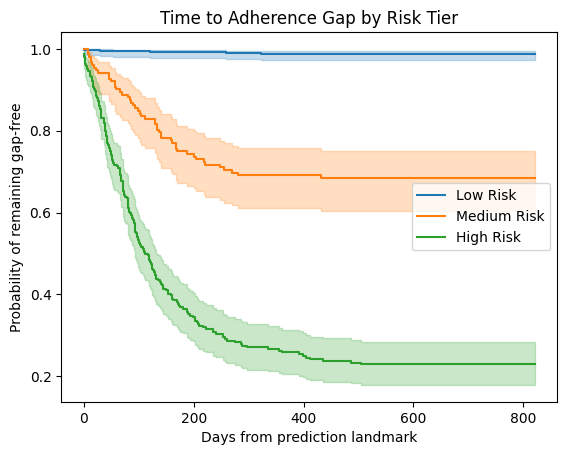

In [503]:
kmf = KaplanMeierFitter()

for tier in [
    "Low Risk",
    "Medium Risk",
    "High Risk"
]:

    mask = (
        test_df["risk_tier"]
        == tier
    )

    kmf.fit(
        test_df.loc[
            mask,
            "time_to_gap_days"
        ],

        test_df.loc[
            mask,
            "event"
        ],

        label=tier
    )

    kmf.plot_survival_function()

plt.xlabel(
    "Days from prediction landmark"
)

plt.ylabel(
    "Probability of remaining gap-free"
)

plt.title(
    "Time to Adherence Gap by Risk Tier"
)

plt.show()

In [339]:
cox_features = [
    "recent_90d_pdc",
    "adherence_trend",
    "gaps_14plus",
    "refill_gap_cv",
    "number_of_unique_drugs",
    "days_since_last_refill",
    "number_of_unique_icd10"
]

In [340]:
cox_df = survival_df[
    ["time_to_gap_days", "event"]
    + cox_features
].copy()

cox_df = cox_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cox_df[cox_features] = scaler.fit_transform(
    cox_df[cox_features]
)

from lifelines import CoxPHFitter

cph = CoxPHFitter(
    penalizer=0.1
)

cph.fit(
    cox_df,
    duration_col="time_to_gap_days",
    event_col="event"
)

cph.print_summary()

<lifelines.CoxPHFitter: fitted with 2910 total observations, 2104 right-censored observations>
             duration col = 'time_to_gap_days'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 2910
number of events observed = 806
   partial log-likelihood = -5745.17
         time fit was run = 2026-10-01 13:54:10 UTC

---
                        coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                               
recent_90d_pdc          0.06      1.06      0.04           -0.03            0.14                0.97                1.15
adherence_trend         0.08      1.08      0.03            0.01            0.14                1.01                1.15
gaps_14plus             0.74      2.10      0.03            0.69            0.80                1.98                2.22
refill_gap_cv           0.04      1.04      0.03           -0.02            0.10                0.98                1.10
number_of_unique_drugs  0.03      1.03      0.03           -0.03            0.10                0.97                1.10
days_since_last_refill -0.48      0.62      0.04           -0.57           -0.39                0.57                0.67
number_of_unique_icd10 -0.01      0.99      0.03           -0.07            0.05                0.93                1.05

                        cmp to      z      p  -log2(p)
covariate                                             
recent_90d_pdc            0.00   1.37   0.17      2.54
adherence_trend           0.00   2.42   0.02      6.02
gaps_14plus               0.00  25.97 <0.005    491.39
refill_gap_cv             0.00   1.38   0.17      2.57
number_of_unique_drugs    0.00   0.98   0.33      1.61
days_since_last_refill    0.00 -10.91 <0.005     89.61
number_of_unique_icd10    0.00  -0.30   0.76      0.39
---
Concordance = 0.86
Partial AIC = 11504.35
log-likelihood ratio test = 1119.85 on 7 df
-log2(p) of ll-ratio test = 786.70

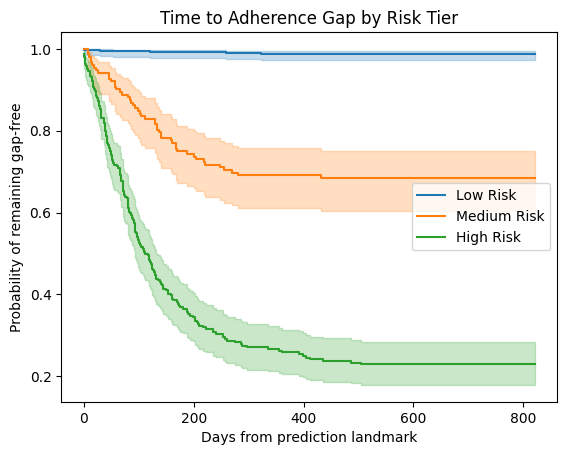

In [504]:
kmf = KaplanMeierFitter()

for tier in [
    "Low Risk",
    "Medium Risk",
    "High Risk"
]:

    mask = (
        test_df["risk_tier"]
        == tier
    )

    kmf.fit(
        test_df.loc[
            mask,
            "time_to_gap_days"
        ],

        test_df.loc[
            mask,
            "event"
        ],

        label=tier
    )

    kmf.plot_survival_function()

plt.xlabel(
    "Days from prediction landmark"
)

plt.ylabel(
    "Probability of remaining gap-free"
)

plt.title(
    "Time to Adherence Gap by Risk Tier"
)

plt.show()

In [102]:
#patient_features.to_csv(
 #   "final_patient_adherence_features.csv",
  #  index=False
#)

In [103]:
#survival_df.to_csv(
 #   "final_survival_modeling_dataset.csv",
  #  index=False
#)

In [342]:
patient_features 

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,number_of_unique_icd10,previous_interventions,previous_failed_interventions,days_since_last_intervention,pdc,CMA,CMG,risk_score,risk_tier,behavior_cluster
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,1.0,1.0,0.0,314.0,0.979381,1.932990,0.020619,2,Medium Risk,0
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,0.0,1.0,0.0,110.0,0.960573,1.218638,0.039427,2,Medium Risk,0
3,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,1.0,3.0,0.0,186.0,0.963048,1.454965,0.036952,4,Medium Risk,2
4,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,0.0,3.0,0.0,182.0,0.878698,0.887574,0.121302,2,Medium Risk,2
5,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,0.0,3.0,2.0,228.0,0.922131,0.983607,0.077869,0,Low Risk,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,1.0,1.0,1.0,209.0,0.978142,0.983607,0.021858,6,High Risk,1
2996,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,0.0,0.0,0.0,NaN,0.996276,1.284916,0.003724,2,Medium Risk,0
2997,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,1.0,0.0,0.0,NaN,0.942113,1.389291,0.057887,2,Medium Risk,2
2998,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,1.0,2.0,0.0,38.0,0.930851,0.957447,0.069149,2,Medium Risk,0


In [343]:
survival_df

,patient_id,median_refill_gap,std_refill_gap,gaps_7plus,gaps_14plus,gaps_30plus,number_of_unique_drugs,refill_gap_cv,consecutive_late_refills,days_since_last_refill,...,days_since_last_intervention,pdc,CMA,CMG,risk_score,risk_tier,behavior_cluster,first_gap_date,time_to_gap_days,event
0,PAT000001,1.5,4.964157,3,1,0,3,3.309438,3,332,...,314.0,0.979381,1.932990,0.020619,2,Medium Risk,0,NaT,821.0,0.0
1,PAT000002,0.5,5.757461,5,1,0,2,11.514921,2,60,...,110.0,0.960573,1.218638,0.039427,2,Medium Risk,0,2024-07-30,211.0,1.0
2,PAT000004,7.0,9.777835,6,4,0,2,1.396834,4,14,...,186.0,0.963048,1.454965,0.036952,4,Medium Risk,2,NaT,821.0,0.0
3,PAT000005,12.0,8.888194,7,4,0,1,0.740683,8,8,...,182.0,0.878698,0.887574,0.121302,2,Medium Risk,2,2025-02-03,399.0,1.0
4,PAT000006,6.5,10.214369,2,1,0,2,1.571441,4,7,...,228.0,0.922131,0.983607,0.077869,0,Low Risk,2,NaT,821.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.0,1.788854,0,0,0,1,0.000000,1,84,...,209.0,0.978142,0.983607,0.021858,6,High Risk,1,NaT,821.0,0.0
2906,PAT002997,0.0,3.940530,2,0,0,2,0.000000,1,32,...,NaN,0.996276,1.284916,0.003724,2,Medium Risk,0,NaT,821.0,0.0
2907,PAT002998,10.0,8.467257,5,3,0,3,0.846726,4,3,...,NaN,0.942113,1.389291,0.057887,2,Medium Risk,2,NaT,821.0,0.0
2908,PAT002999,1.0,3.435113,1,0,0,1,3.435113,2,348,...,38.0,0.930851,0.957447,0.069149,2,Medium Risk,0,NaT,821.0,0.0
